In [1]:
import sys
import os


import numpy as np
import matplotlib.pyplot as plt
import scipy
import astropy.units as u
from astropy.time import Time
import astropy.cosmology as acosmo
from astropy.coordinates import SkyCoord
from astropy.table import QTable
import astropy_healpix as ah
import pandas as pd
from scipy.interpolate import interp1d
import ligo.skymap.plot #used implicitely
import mhealpy as mhp
import healpy as hp
import copy
from firesong.Firesong import firesong_simulation
from firesong.FluxPDF import flux_pdf
from scipy.special import factorial


sys.path.insert(1, '/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/Rubicube')
from transient_rates import R_SFR, R_TDE, R_sGRB_gaus, plot_rates
from params import p_cosmology, p
from ic_visualization_clean import read_map, plot_map, evaluate_map, get_map_area, \
    get_moc_map_metadata, get_max_ra_dec_from_map, is_source_in_contour_area
from Rubicube import effective_area, signal_energy_pdf


/Users/cristozilleruelo/.local/share/mamba/envs/AMPEL/lib/python3.14/site-packages/igwn_ligolw/lsctables.py:57: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


In [2]:
time = (100 * u.d).to(u.s).value
sim_values = firesong_simulation('./', density=1e-6, Evolution='CC2015SNR', zmax=10.0,
                    fluxnorm=1.44e-8, index=2.53, LF='SC', Transient=True, timescale=time,
                    filename=None)
sim_values

##############################################################################
##### FIRESONG initializing  - Calculating Neutrino CDFs #####
Standard candle sources+
Transient Sources, time scale = 8640000.0s
Source evolution assumed: CC2015SNR
Local density of neutrino sources: 1e-06/Mpc^3
Total number of neutrinos sources in the Universe: 2423376
Redshift range: 0 - 10.0
Standard Candle Luminosity: 7.2363e+50 erg/yr
##### FIRESONG initialization done #####

Actual diffuse flux simulated :
E^2 dNdE = 2.0218738326101494e-08 (E/100 TeV)^(-0.5299999999999998) [GeV/cm^2.s.sr]


{'header': {'LF': 'SC',
  'Transient': True,
  'timescale': np.float64(8640000.0),
  'fluxnorm': 1.44e-08,
  'delta_gamma': -0.5299999999999998,
  'luminosity': np.float64(7.236281583487355e+50)},
 'total_flux': np.float64(2.0218738326101494e-08),
 'sources': {'dec': array([-39.69912656,  46.62797456, -41.56945193, ...,  36.96162192,
          33.07810817, -29.94690599], shape=(2423376,)),
  'ra': array([199.22154342, 167.68527484, 147.34217902, ...,  48.17038092,
         201.27226602, 278.77381743], shape=(2423376,)),
  'flux': array([1.18554583e-14, 5.92878914e-16, 2.44915922e-12, ...,
         1.10683374e-13, 3.07596260e-14, 1.90631113e-15], shape=(2423376,)),
  'z': array([2.10211612, 4.88494961, 0.38922347, ..., 1.08410858, 1.59238423,
         3.5299439 ], shape=(2423376,))}}

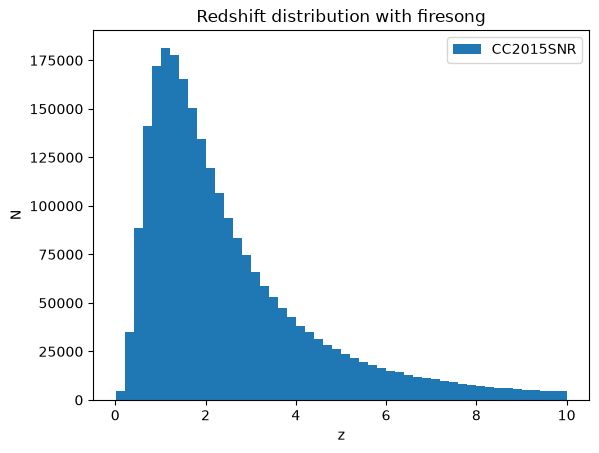

In [3]:
plt.hist(sim_values['sources']['z'], bins=50, label='CC2015SNR')
plt.xlabel('z')
plt.ylabel('N')
plt.title('Redshift distribution with firesong')
plt.legend()
plt.show()

In [4]:
hist, bin_edges  = np.histogram(sim_values['sources']['z'], bins=50)
len(hist) == len(bin_edges[:-1])


True

In [5]:
def R_SFR(z, R0=1):
    '''
    From Madau & Dickinson 2014
    '''
    
    # return 0.0068*0.0015*(1 + z)**2.7/(1 + ((1 + z)/2.9)**5.6) * (u.Mpc ** -3 * u.yr ** -1)
    return R0 * (1 + z)**2.7/(1 + ((1 + z)/2.9)**5.6) 

In [6]:
def get_N_k_firesong(phi_z, R0, z_max=10, z_local=0.00023, p=p_cosmology, sky_area=4*np.pi*u.sr, time_window=None):

    R0 = R0.to(u.Mpc**-3 * u.yr ** -1)
    cosmo = acosmo.LambdaCDM(H0=p['h0']* u.km / u.s / u.Mpc, 
                             Om0=p['omega_M'],
                            Ode0=p['omega_L'])#, Tcmb0=2.725 * u.K,
    V_local = cosmo.comoving_volume(z_local)

    z_range_local = np.linspace(p['z_min'], z_local, 10000)
    z_range_max = np.linspace(p['z_min'], z_max, 10000)
    dVdz_max = cosmo.differential_comoving_volume(z_range_max)
    dVdz_local = cosmo.differential_comoving_volume(z_range_local)

    y_z_max = phi_z(z_range_max) * dVdz_max / (1 + z_range_max)
    y_z_local = phi_z(z_range_local) * dVdz_local / (1 + z_range_local) 

    N_k = R0 * V_local * scipy.integrate.trapezoid(y_z_max, z_range_max) / scipy.integrate.trapezoid(y_z_local, z_range_local) 
    if time_window is not None:
            #check if its in [yr]
            if not isinstance(time_window, u.Quantity):
                "Time window given has no specified unit. Assuming [yr]"
                time_window = time_window * u.yr
            #change to yr if different
            time_window = time_window.to(u.yr)
            return N_k * time_window
    return N_k

def firesong_rate(phi_z, z, R0):
     return R0 * phi_z(z) / phi_z(0)

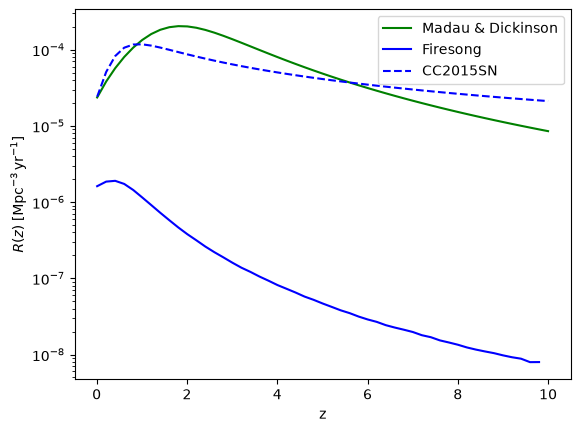

In [7]:
from firesong.Evolution import CandelsClash2015SNRate 
firesong_phi_model = CandelsClash2015SNRate()


R0_sn_ia = p_cosmology['R0']['SN Ia'].to(u.Mpc**-3*u.yr**-1)

cosmo = acosmo.LambdaCDM(H0=p_cosmology['h0']* u.km / u.s / u.Mpc, 
                         Om0= p_cosmology['omega_M'],
                        Ode0=p_cosmology['omega_L'])#, Tcmb0=2.725 * u.K,
# dVdz = cosmo.differential_comoving_volume(bin_edges[:-1]) * 4 * np.pi * u.sr
dVdz = np.diff(cosmo.comoving_volume(bin_edges))
simulated_rate = hist / dVdz / (1 + bin_edges[:-1])
plt.plot(bin_edges, R_SFR(bin_edges, R0=R0_sn_ia), label='Madau & Dickinson', c='green')
plt.plot(bin_edges[:-1], simulated_rate, label='Firesong', c='blue')
plt.plot(bin_edges, firesong_rate(firesong_phi_model, bin_edges, R0=R0_sn_ia) , label='CC2015SN', color='blue', linestyle='dashed')
plt.yscale('log')
plt.legend()
plt.ylabel(r"$R(z)\;[\text{Mpc}^{-3}\,\text{yr}^{-1}]$")
plt.xlabel('z')
plt.show()

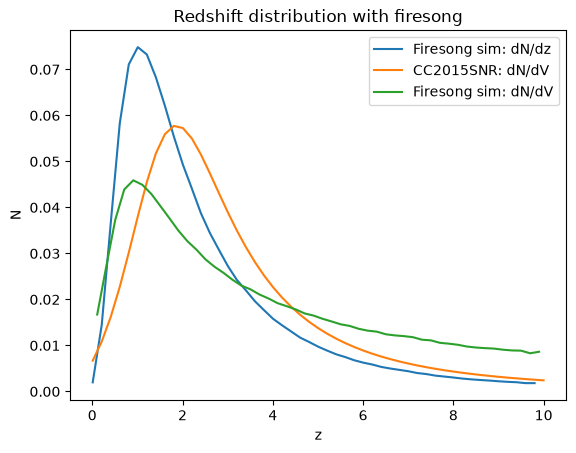

In [16]:
hist_values, bin_edges = np.histogram(sim_values['sources']['z'], bins=50)
norm_dN_dz = hist_values / np.sum(hist_values)

norm_rate = R_SFR(bin_edges, R0=R0_sn_ia) / np.sum(R_SFR(bin_edges, R0=R0_sn_ia))

dVdz = np.diff(cosmo.comoving_volume(bin_edges))
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

simulated_rate = hist_values / dVdz * (1 + bin_centers)
norm_simulated_rate = simulated_rate / np.sum(simulated_rate)



plt.plot(bin_edges[:-1], norm_dN_dz, label='Firesong sim: dN/dz')
plt.plot(bin_edges, norm_rate, label='CC2015SNR: dN/dV')
plt.plot(bin_centers, norm_simulated_rate, label='Firesong sim: dN/dV')
plt.xlabel('z')
plt.ylabel('N')
plt.title('Redshift distribution with firesong')
plt.legend()
plt.show()